# 3. Квантильная регрессия

**Основная идея:** напрямую моделируем квантили, получая адаптивные интервалы (ширина зависит от признаков).

В этом ноутбуке:
- Pinball loss — почему её минимум даёт квантиль;
- QAR (Quantile Autoregression) через sklearn `QuantileRegressor`;
- CatBoost Quantile vs MultiQuantile, пересечение квантилей;
- CQR (Conformalized Quantile Regression) — возвращаем покрытие;
- финальное сравнение всех методов блока.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import QuantileRegressor
from catboost import CatBoostRegressor
from conformalforecast import ConformalizedQuantileRegression

sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 4)

## 0. Данные

Те же AEP дневные, что и в предыдущих ноутбуках.

In [2]:
df_hour = pd.read_csv('../data/AEP_hourly.csv', parse_dates=['Datetime'])
df_hour.columns = ['timestamp', 'target']

df_day = df_hour.resample('D', on='timestamp').sum().reset_index()
df_day = df_day.rename(columns={'timestamp': 'ds', 'target': 'y'})
df_day = df_day[df_day["ds"] < "2018-08-03"]

split_point = int(len(df_day) * 0.8)
train = df_day.iloc[:split_point].copy()
test = df_day.iloc[split_point:].copy()

print(f"Train: {len(train)}, Test: {len(test)}")

Train: 4043, Test: 1011


## 1. Pinball loss

Для квантиля уровня τ:

$$L_τ(y, q) = \begin{cases} τ(y - q), & y ≥ q \\ (1-τ)(q - y), & y < q \end{cases}$$

Минимизация E[L_τ(y, q)] даёт τ-квантиль распределения y.

In [3]:
# Демонстрация на синтетике
np.random.seed(42)
y_demo = np.random.normal(100, 15, 1000)

# Кандидаты для квантиля
q_candidates = np.linspace(50, 150, 200)

def pinball_loss(y, q, tau):
    return np.where(y >= q, tau * (y - q), (1 - tau) * (q - y))

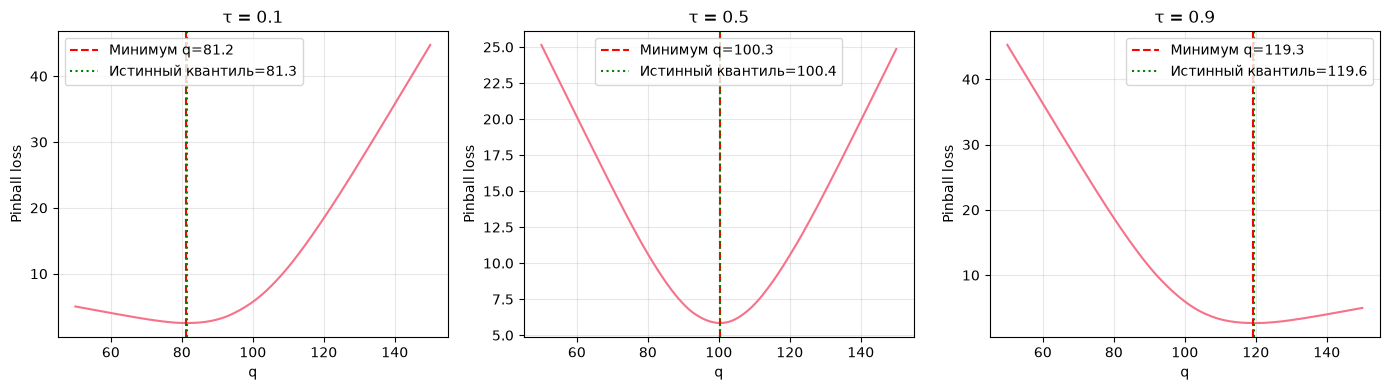

Минимум pinball loss совпадает с эмпирическим квантилем.


In [4]:
# Потери для разных τ
taus = [0.1, 0.5, 0.9]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, tau in zip(axes, taus):
    losses = [pinball_loss(y_demo, q, tau).mean() for q in q_candidates]
    q_min = q_candidates[np.argmin(losses)]

    ax.plot(q_candidates, losses)
    ax.axvline(q_min, color='red', linestyle='--', label=f'Минимум q={q_min:.1f}')
    ax.axvline(np.quantile(y_demo, tau), color='green', linestyle=':', label=f'Истинный квантиль={np.quantile(y_demo, tau):.1f}')
    ax.set_title(f'τ = {tau}')
    ax.set_xlabel('q')
    ax.set_ylabel('Pinball loss')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Минимум pinball loss совпадает с эмпирическим квантилем.")

## 2. QAR (Quantile Autoregression)

Модель: $q_τ(y_t) = φ_0(τ) + φ_1(τ) y_{t-1} + ... + φ_p(τ) y_{t-p}$

Оцениваем через `sklearn.linear_model.QuantileRegressor`.

Обратите внимание на `alpha=0.0`: это **L1-регуляризация**, включённая по умолчанию
(`alpha=1.0`), и она подмешивает к pinball-потере штраф на коэффициенты. Нам нужна
чистая квантильная регрессия, поэтому регуляризацию выключаем явно.

In [5]:
# Признаки: лаги
def make_ar_features(series, lags=list(range(1, 8))):
    df = pd.DataFrame({'y': series.values})
    for lag in lags:
        df[f'lag_{lag}'] = df['y'].shift(lag)
    df = df.dropna()
    return df

In [6]:
df_ar = make_ar_features(train['y'], lags=list(range(1, 15)))
X_train_ar = df_ar[[c for c in df_ar.columns if c.startswith('lag_')]]
y_train_ar = df_ar['y']

# Тестовая выборка
df_ar_test = make_ar_features(pd.concat([train['y'], test['y']]).reset_index(drop=True), lags=list(range(1, 15)))
df_ar_test = df_ar_test.iloc[len(df_ar):].reset_index(drop=True)
X_test_ar = df_ar_test[[c for c in df_ar_test.columns if c.startswith('lag_')]]
y_test_ar = df_ar_test['y']

In [7]:
# Оценка квантилей 0.025, 0.5, 0.975
quantiles = [0.025, 0.5, 0.975]
qar_predictions = {}

for tau in quantiles:
    qr = QuantileRegressor(quantile=tau, alpha=0.0, solver='highs')
    qr.fit(X_train_ar, y_train_ar)
    qar_predictions[tau] = qr.predict(X_test_ar)

    print(f"\nКвантиль τ={tau}:")
    print(f"  Коэффициенты: {np.round(qr.coef_[:3], 4)}...")


Квантиль τ=0.025:
  Коэффициенты: [ 0.9792 -0.3679  0.0851]...

Квантиль τ=0.5:
  Коэффициенты: [ 1.0884 -0.4795  0.1881]...

Квантиль τ=0.975:
  Коэффициенты: [ 1.0683 -0.4582  0.1664]...



Квантиль τ=0.5:
  Коэффициенты: [ 1.0884 -0.4796  0.188 ]...



Квантиль τ=0.975:
  Коэффициенты: [ 1.0683 -0.4582  0.1664]...


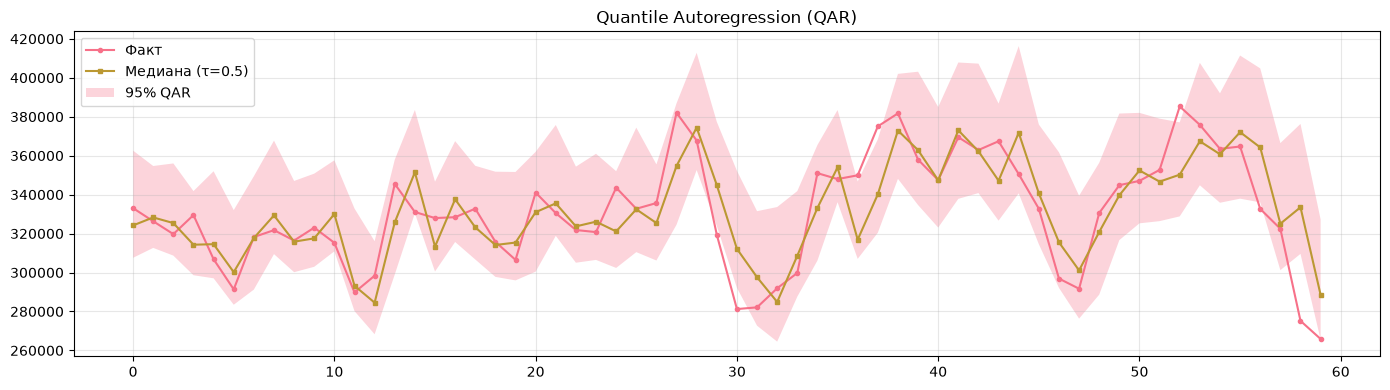

In [8]:
# Визуализация первых 60 точек
plt.figure(figsize=(14, 4))
plt.plot(range(60), y_test_ar.values[:60], 'o-', label='Факт', markersize=3)
plt.plot(range(60), qar_predictions[0.5][:60], 's-', label='Медиана (τ=0.5)', markersize=3)
plt.fill_between(range(60), qar_predictions[0.025][:60], qar_predictions[0.975][:60], alpha=0.3, label='95% QAR')
plt.legend()
plt.title('Quantile Autoregression (QAR)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Покрытие
coverage_qar = ((y_test_ar.values >= qar_predictions[0.025]) & (y_test_ar.values <= qar_predictions[0.975])).mean()
print(f"Покрытие QAR: {coverage_qar:.3f}")

Покрытие QAR: 0.904


### Асимметрия: φ(τ) зависит от квантиля

Коэффициенты квантильной регрессии зависят от τ — это и есть её главное отличие от
МНК, который даёт одну модель на все квантили. Смотрим на два числа: `lag_1` (сила
связи с последним днём) и **сумму** всех AR-коэффициентов — она показывает, насколько
система инерционна в целом.

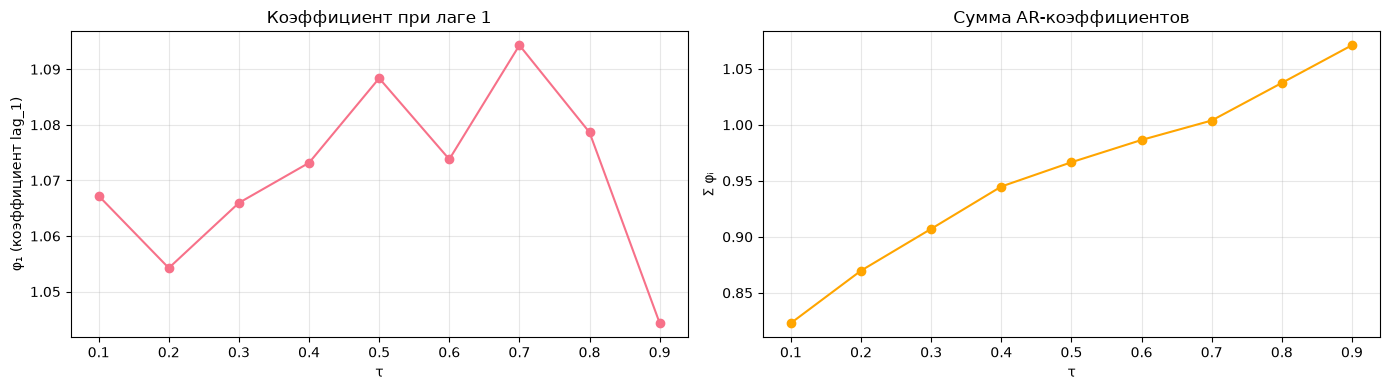

φ₁ (lag_1): min=1.0443, max=1.0943, разброс=0.0500
Σ φᵢ:       min=0.8230, max=1.0710, разброс=0.2480

Σ φᵢ монотонно растёт с τ: True
У верхних квантилей система инерционнее: пики подхватывают историю сильнее, чем провалы. На нижних квантилях сумма < 1 (возврат к среднему), на высоких — > 1.


In [10]:
# Визуализация коэффициентов
taus_demo = np.linspace(0.1, 0.9, 9)
coef_by_tau = {}
sum_by_tau = {}

for tau in taus_demo:
    qr = QuantileRegressor(quantile=tau, alpha=0.0, solver='highs').fit(X_train_ar, y_train_ar)
    coef_by_tau[tau] = qr.coef_[0]      # lag_1
    sum_by_tau[tau] = qr.coef_.sum()    # сумма всех лаговых коэффициентов

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(list(coef_by_tau.keys()), list(coef_by_tau.values()), 'o-')
axes[0].set_xlabel('τ')
axes[0].set_ylabel('φ₁ (коэффициент lag_1)')
axes[0].set_title('Коэффициент при лаге 1')
axes[0].grid(alpha=0.3)

axes[1].plot(list(sum_by_tau.keys()), list(sum_by_tau.values()), 'o-', color='orange')
axes[1].set_xlabel('τ')
axes[1].set_ylabel('Σ φᵢ')
axes[1].set_title('Сумма AR-коэффициентов')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"φ₁ (lag_1): min={min(coef_by_tau.values()):.4f}, max={max(coef_by_tau.values()):.4f}, "
      f"разброс={max(coef_by_tau.values()) - min(coef_by_tau.values()):.4f}")
print(f"Σ φᵢ:       min={min(sum_by_tau.values()):.4f}, max={max(sum_by_tau.values()):.4f}, "
      f"разброс={max(sum_by_tau.values()) - min(sum_by_tau.values()):.4f}")
print(f"\nΣ φᵢ монотонно растёт с τ: "
      f"{all(np.diff(list(sum_by_tau.values())) > 0)}")
print("У верхних квантилей система инерционнее: пики подхватывают историю сильнее, "
      "чем провалы. На нижних квантилях сумма < 1 (возврат к среднему), на высоких — > 1.")

## 3. CatBoost для квантилей

CatBoost поддерживает `Quantile:alpha=...` (одна модель на квантиль) и `MultiQuantile` (одна модель на все квантили).

In [11]:
# Признаки: лаги + календарь
def make_features_cb(df, lags=list(range(14, 28))):
    df = df.copy()
    df['dow'] = df['ds'].dt.dayofweek
    df['month'] = df['ds'].dt.month

    for lag in lags:
        df[f'lag_{lag}'] = df['y'].shift(lag)

    df = df.dropna()
    return df

In [12]:
df_cb = make_features_cb(df_day)

# dropna() выбросил первые 27 строк (максимальный лаг), поэтому граница train/test
# внутри df_cb сдвинута относительно исходного split_point ровно на это число.
n_dropped = len(df_day) - len(df_cb)
cut_cb = split_point - n_dropped
print(f"Выброшено строк с NaN-лагами: {n_dropped}; граница train/test: {cut_cb}")

feat_cols = ['dow', 'month'] + [c for c in df_cb.columns if c.startswith('lag_')]

X_train_cb = df_cb.iloc[:cut_cb][feat_cols]
y_train_cb = df_cb.iloc[:cut_cb]['y']

X_test_cb = df_cb.iloc[cut_cb:][feat_cols]
y_test_cb = df_cb.iloc[cut_cb:]['y']

assert len(X_test_cb) == len(test), "тестовая часть CatBoost должна совпадать с test"
print(f"Train: {len(X_train_cb)} (до {df_cb['ds'].iloc[cut_cb - 1].date()}), "
      f"Test: {len(X_test_cb)} (с {df_cb['ds'].iloc[cut_cb].date()})")

Выброшено строк с NaN-лагами: 27; граница train/test: 4016
Train: 4016 (до 2015-10-26), Test: 1011 (с 2015-10-27)


In [13]:
# Отдельные модели Quantile
cb_quantiles = {}

for tau in [0.025, 0.5, 0.975]:
    cb = CatBoostRegressor(
        iterations=200,
        depth=4,
        loss_function=f'Quantile:alpha={tau}',
        verbose=False,
        random_state=42
    )
    cb.fit(X_train_cb, y_train_cb)
    cb_quantiles[tau] = cb.predict(X_test_cb)

In [14]:
# MultiQuantile: одна модель на все квантили
cb_multi = CatBoostRegressor(
    iterations=200,
    depth=4,
    loss_function='MultiQuantile:alpha=0.025,0.5,0.975',
    verbose=False,
    random_state=42
)
cb_multi.fit(X_train_cb, y_train_cb)

# Прогноз возвращает матрицу (n_samples, n_quantiles)
preds_multi = cb_multi.predict(X_test_cb)

cb_multi_quantiles = {
    0.025: preds_multi[:, 0],
    0.5: preds_multi[:, 1],
    0.975: preds_multi[:, 2]
}

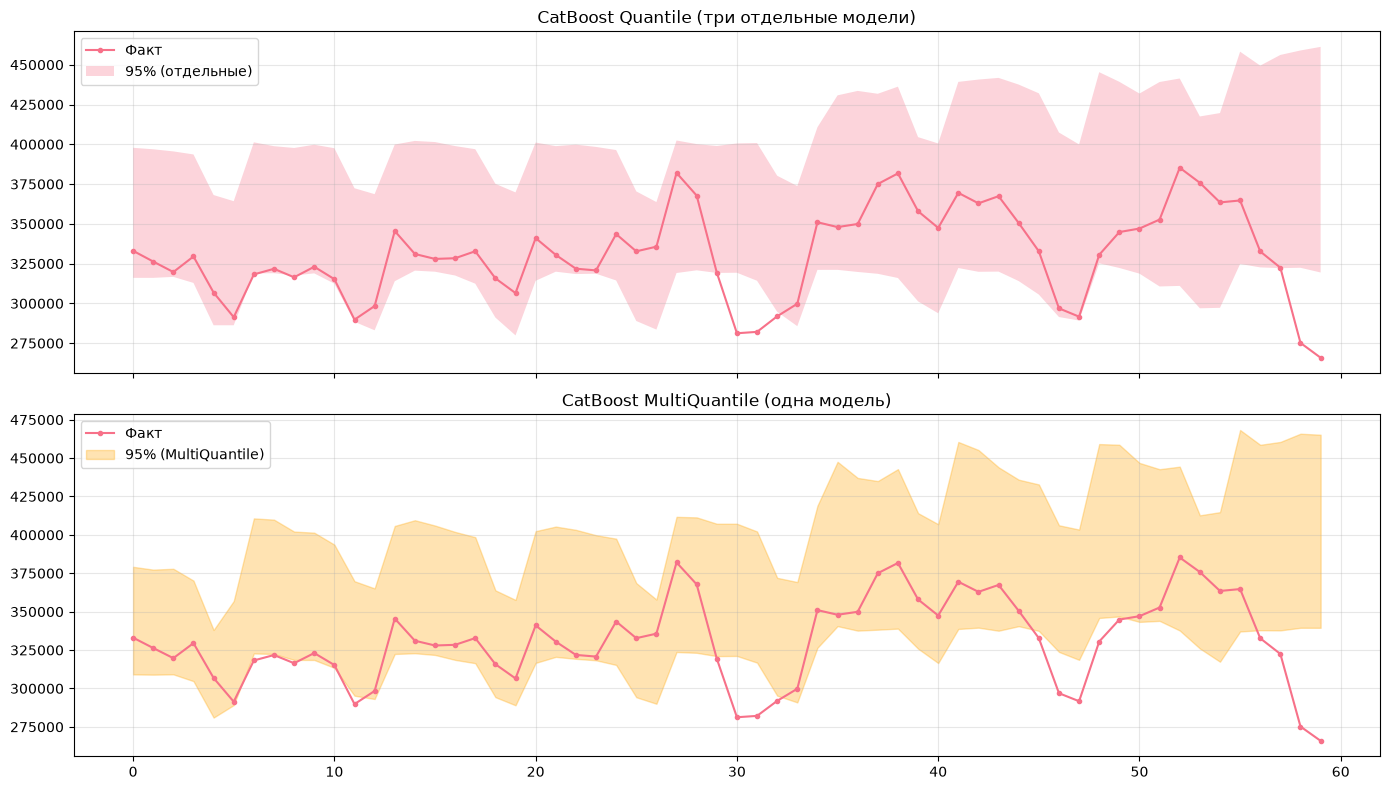

In [15]:
# Визуализация: сравнение отдельных моделей и MultiQuantile
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Отдельные модели
axes[0].plot(range(60), y_test_cb.values[:60], 'o-', label='Факт', markersize=3)
axes[0].fill_between(range(60), cb_quantiles[0.025][:60], cb_quantiles[0.975][:60], alpha=0.3, label='95% (отдельные)')
axes[0].set_title('CatBoost Quantile (три отдельные модели)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# MultiQuantile
axes[1].plot(range(60), y_test_cb.values[:60], 'o-', label='Факт', markersize=3)
axes[1].fill_between(range(60), cb_multi_quantiles[0.025][:60], cb_multi_quantiles[0.975][:60], alpha=0.3, label='95% (MultiQuantile)', color='orange')
axes[1].set_title('CatBoost MultiQuantile (одна модель)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Пересечение квантилей

Квантили обязаны быть упорядочены: q₀.₀₂₅ ≤ q₀.₅ ≤ q₀.₉₇₅. Отдельные модели учатся
независимо друг от друга, поэтому теоретически могут это нарушить. Проверяем все три
уровня, а не только крайние.

In [16]:
# Проверка пересечений: сравниваем все соседние уровни
def count_crossings(quantile_dict):
    levels = sorted(quantile_dict)
    return sum(
        np.sum(quantile_dict[lo] > quantile_dict[hi])
        for lo, hi in zip(levels, levels[1:])
    )


violations_separate = count_crossings(cb_quantiles)
violations_multi = count_crossings(cb_multi_quantiles)

for name, n_viol in [('отдельные модели', violations_separate),
                     ('MultiQuantile', violations_multi)]:
    print(f"Пересечений ({name}): {n_viol} из {len(y_test_cb)} "
          f"({100 * n_viol / len(y_test_cb):.1f}%)")

if violations_separate == 0 and violations_multi == 0:
    print("\nНа этом ряду пересечений нет ни у одного варианта: данные достаточно "
          "гладкие, и упорядоченность сохраняется сама. На шумных рядах отдельные "
          "модели её нарушают, и тогда нужна постобработка (сортировка или одна "
          "модель MultiQuantile).")
else:
    print("\nMultiQuantile обучает квантили совместно и пересечений не даёт.")

Пересечений (отдельные модели): 0 из 1011 (0.0%)
Пересечений (MultiQuantile): 0 из 1011 (0.0%)

На этом ряду пересечений нет ни у одного варианта: данные достаточно гладкие, и упорядоченность сохраняется сама. На шумных рядах отдельные модели её нарушают, и тогда нужна постобработка (сортировка или одна модель MultiQuantile).


## 4. CQR (Conformalized Quantile Regression)

**Проблема:** квантили, оценённые независимо, не гарантируют покрытие вне выборки (лонгрид с. 6).

**Решение:** конформная калибровка квантилей — CQR сохраняет адаптивную ширину и возвращает покрытие.

API `conformalforecast` тут array-based: метод конфигурируется один раз (`alpha` в конструкторе),
а данные подаются «кубом квантилей» формы `(n_series, n_samples, horizon, 2)`, где последняя
ось — это `(q_lo, q_hi)`. Мы работаем с одним рядом, поэтому `n_series = 1`, а `horizon = 1`.

In [17]:
# Разбиение на train / calib / test
calib_size = 100

X_train_cqr = X_train_cb.iloc[:-calib_size]
y_train_cqr = y_train_cb.iloc[:-calib_size]

X_calib_cqr = X_train_cb.iloc[-calib_size:]
y_calib_cqr = y_train_cb.iloc[-calib_size:]

In [18]:
# Параметр alpha задаётся в конструкторе: это целевой уровень ошибки, coverage = 1 - alpha
alpha = 0.05
cqr = ConformalizedQuantileRegression(alpha=alpha)


def q_cube(lower, upper):
    """Складываем пару квантилей в куб (n_series, n_samples, horizon, 2)."""
    return np.stack([np.asarray(lower), np.asarray(upper)], axis=-1)[None, :, None, :]

In [19]:
# Обучаем квантильные модели на train
cb_lower = CatBoostRegressor(iterations=200, depth=4, loss_function='Quantile:alpha=0.025', verbose=False, random_state=42)
cb_upper = CatBoostRegressor(iterations=200, depth=4, loss_function='Quantile:alpha=0.975', verbose=False, random_state=42)

cb_lower.fit(X_train_cqr, y_train_cqr)
cb_upper.fit(X_train_cqr, y_train_cqr)

# Прогнозы на калибровке
q_lower_calib = cb_lower.predict(X_calib_cqr)
q_upper_calib = cb_upper.predict(X_calib_cqr)

In [20]:
# Калибровка CQR: fit — на отложенной калибровочной выборке
fitted_cqr = cqr.fit(
    q_cube(q_lower_calib, q_upper_calib),
    y_calib_cqr.values[None, :, None],
)

print(f"Размер калибровочной выборки: {fitted_cqr.n_calibration_samples_}")
print(f"Конформный квантиль поправки: {fitted_cqr.score_quantile_[0, 0]:+.1f}")
print("Поправка > 0 => исходные квантили слишком узкие, интервал расширяем.")

Размер калибровочной выборки: [100]
Конформный квантиль поправки: +9661.6
Поправка > 0 => исходные квантили слишком узкие, интервал расширяем.


In [21]:
# Прогнозы на тесте
q_lower_test = cb_lower.predict(X_test_cb)
q_upper_test = cb_upper.predict(X_test_cb)

# interval — расширяем пару квантилей на откалиброванную поправку
cqr_interval = fitted_cqr.interval(q_cube(q_lower_test, q_upper_test))
lower_cqr = cqr_interval[0, :, 0, 0]
upper_cqr = cqr_interval[0, :, 0, 1]

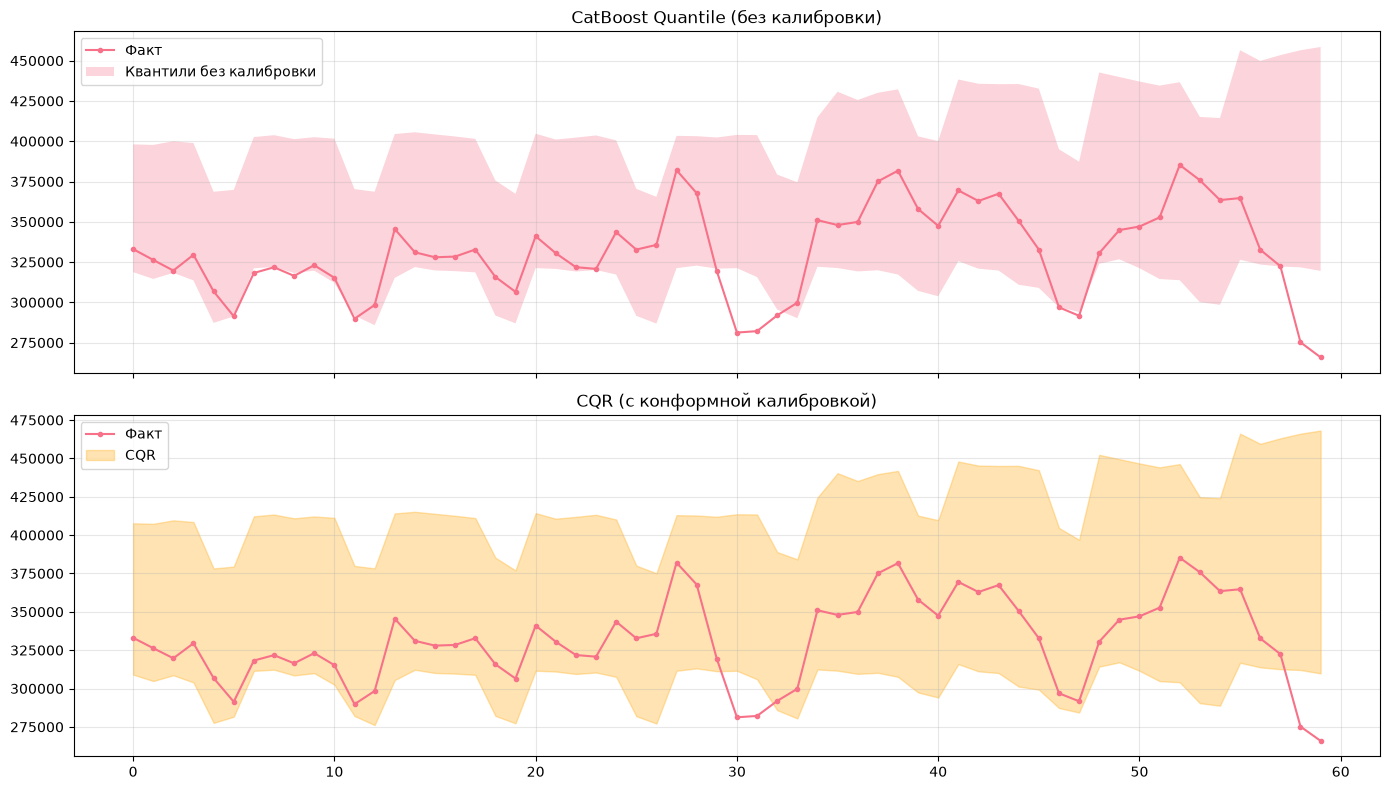

In [22]:
# Сравнение: квантили без калибровки vs CQR
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Без калибровки
axes[0].plot(range(60), y_test_cb.values[:60], 'o-', label='Факт', markersize=3)
axes[0].fill_between(range(60), q_lower_test[:60], q_upper_test[:60], alpha=0.3, label='Квантили без калибровки')
axes[0].set_title('CatBoost Quantile (без калибровки)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# С калибровкой (CQR)
axes[1].plot(range(60), y_test_cb.values[:60], 'o-', label='Факт', markersize=3)
axes[1].fill_between(range(60), lower_cqr[:60], upper_cqr[:60], alpha=0.3, label='CQR', color='orange')
axes[1].set_title('CQR (с конформной калибровкой)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
coverage_no_calib = ((y_test_cb.values >= q_lower_test) & (y_test_cb.values <= q_upper_test)).mean()
coverage_cqr = ((y_test_cb.values >= lower_cqr) & (y_test_cb.values <= upper_cqr)).mean()
nominal = 1 - alpha

print(f"Покрытие без калибровки: {coverage_no_calib:.3f}")
print(f"Покрытие CQR: {coverage_cqr:.3f} (номинал {nominal:.3f})")
print(f"Отклонение CQR от номинала: {coverage_cqr - nominal:+.3f}")

print("\nЧто происходит:")
print(f"  - без калибровки покрытие {coverage_no_calib:.3f} — сильно ниже номинала;")
print(f"  - CQR сдвигает его к {coverage_cqr:.3f}, но не точно в {nominal:.3f}.")

Покрытие без калибровки: 0.825
Покрытие CQR: 0.941 (номинал 0.950)
Отклонение CQR от номинала: -0.009

Что происходит:
  - без калибровки покрытие 0.825 — сильно ниже номинала;
  - CQR сдвигает его к 0.941, но не точно в 0.950.


## 5. Финальное сравнение всех методов блока

Сравниваем coverage, width, Winkler score всех методов из трёх ноутбуков.

In [24]:
# Хелпер для метрик
def interval_metrics(y_true, lower, upper, level=0.95):
    coverage = ((y_true >= lower) & (y_true <= upper)).mean()
    width = (upper - lower).mean()

    alpha = 1 - level
    winkler = (upper - lower) + (2/alpha) * (lower - y_true) * (y_true < lower) + (2/alpha) * (y_true - upper) * (y_true > upper)
    winkler = winkler.mean()

    return {'coverage': coverage, 'width': width, 'winkler': winkler}

In [25]:
# Собираем результаты (используем те же прогнозы, что выше)
results = []

# QAR
results.append({
    'Метод': 'QAR (QuantileRegressor)',
    **interval_metrics(y_test_ar.values, qar_predictions[0.025], qar_predictions[0.975])
})

# CatBoost Quantile
results.append({
    'Метод': 'CatBoost Quantile',
    **interval_metrics(y_test_cb.values, cb_quantiles[0.025], cb_quantiles[0.975])
})

# CatBoost MultiQuantile
results.append({
    'Метод': 'CatBoost MultiQuantile',
    **interval_metrics(y_test_cb.values, cb_multi_quantiles[0.025], cb_multi_quantiles[0.975])
})

# CQR
results.append({
    'Метод': 'CQR',
    **interval_metrics(y_test_cb.values, lower_cqr, upper_cqr)
})

In [26]:
results_df = pd.DataFrame(results)
print("\nФинальное сравнение методов блока 1 (квантильная регрессия):\n")
print(results_df.to_string(index=False))


Финальное сравнение методов блока 1 (квантильная регрессия):

                  Метод  coverage         width       winkler
QAR (QuantileRegressor)  0.904055  65334.109472  98700.674725
      CatBoost Quantile  0.818002 113616.583480 182529.921245
 CatBoost MultiQuantile  0.816024 103298.483663 198127.841509
                    CQR  0.940653 133591.568363 159157.731792


In [27]:
# Короткий разбор таблицы: кто ближе к номиналу и кто даёт самые узкие интервалы
nominal = 0.95
best_cov = results_df.iloc[(results_df['coverage'] - nominal).abs().argmin()]

print(f"Ближе всех к покрытию {nominal:.2f}: {best_cov['Метод']} "
      f"({best_cov['coverage']:.3f})")

# Сравнивать ширину честно можно только при сопоставимом покрытии — иначе
# побеждает тот, кто просто рисует узкий интервал и чаще промахивается.
near_nominal = results_df[(results_df['coverage'] - nominal).abs() <= 0.03]
if len(near_nominal) > 1:
    narrowest = near_nominal.loc[near_nominal['width'].idxmin()]
    print(f"При покрытии в пределах ±0.03 от номинала самый узкий интервал: "
          f"{narrowest['Метод']} (ширина {narrowest['width']:.0f})")
elif len(near_nominal) == 1:
    print("Единственный метод с покрытием, близким к номиналу: "
          f"{near_nominal.iloc[0]['Метод']} — сравнивать ширину не с чем, "
          "остальные занижают покрытие.")

print(f"Самый низкий Winkler score: "
      f"{results_df.loc[results_df['winkler'].idxmin(), 'Метод']} — "
      "он штрафует и за ширину, и за промахи, поэтому честнее всего для сравнения.")

Ближе всех к покрытию 0.95: CQR (0.941)
Единственный метод с покрытием, близким к номиналу: CQR — сравнивать ширину не с чем, остальные занижают покрытие.
Самый низкий Winkler score: QAR (QuantileRegressor) — он штрафует и за ширину, и за промахи, поэтому честнее всего для сравнения.


## Итоговая памятка: когда что брать

| Метод | Когда использовать | Плюсы | Минусы |
|-------|-------------------|-------|--------|
| Аналитические (ETS/ARIMA) | Модель точно подходит, ряд стационарен | Быстро, теоретически обоснованно | Занижает покрытие при неверной модели |
| NaiveVariance / Empirical | Есть кросс-валидация, модель любая | Простота, σ по горизонту | Остатки in-sample оптимистичны |
| Бутстреп остатков | i.i.d. ошибки, нужна неопределённость шума | Учитывает случайность | Не учитывает неопределённость параметров |
| Бэггинг (block bootstrap) | Автокорреляция, нужна неопределённость модели | Учитывает зависимость | Медленно |
| Split Conformal | Перестановочность, модель любая | Гарантия покрытия | Одинаковая ширина для всех точек |
| ACI / AgACI | Дрейф, гетероскедастичность | Адаптация онлайн | Сложнее настроить |
| QAR | Нужны асимметричные интервалы | Адаптивная ширина | Покрытие вне выборки не гарантировано |
| CQR | Квантильная регрессия + гарантия покрытия | Адаптивность + калибровка | Требует калибровочной выборки |

**Общий вывод блока:** для надёжных интервалов нужна калибровка на отложенных данных. Конформные методы дают гарантии при перестановочности; квантильная регрессия даёт адаптивную ширину; CQR объединяет оба подхода.